<div align="center">

# WEEK 05
## INVENTORY HEALTH, TURNOVER & AGEING

### CadetX Virtual Work Experience
### Heavy Supplier, Inventory & Warehouse Analytics

</div>

---

| | |
|---|---|
| **Prepared by** | Keren Oyem |
| **Role** | Data Analyst / Data Scientist (solo sprint) |
| **Sprint** | Week 5 · Fri 20 Nov – Thu 26 Nov 2026 |
| **Catalogue tasks** | B3 Slow-Moving & Dead Stock · B4 Inventory Turnover · B5 Stock Health Assessment · B6 Inventory Aging · B8 Overstock & Understock Detection |
| **Data source** | `data/processed/*.parquet` (the Week 2 cleaned layer) |
| **Tools** | Python, pandas, DuckDB, matplotlib |

## Objective

Quantify inventory health for every product-branch pair (180 in total), the capital tied up in excess stock, and the stock that is old or not moving. Then explain **why** stock keeps building up.

## Data used

| Table | Used for |
|---|---|
| `stock_ledger` | Rebuilding stock positions and FIFO layers |
| `inventory_master` | Opening stock and **branch-level** reorder, safety and max levels |
| `products` | `unit_cost` (valuation), category, criticality |
| `sales_orders_header` / `_lines` | COGS, units sold, recency of demand |
| `purchase_orders_header` / `_lines` | Root-cause analysis of the inflow vs outflow imbalance |
| `branches` | Branch names |

## Results summary

The headline numbers are generated live in **Section 8** from the data, so they cannot drift from the analysis. Read Section 8 first, then the sections behind it.

## Assumptions (Definition of Done)

| # | Assumption | Why |
|---|---|---|
| A1 | **Stock is rebuilt from the ledger**: opening + IN − OUT, as of the reference date | Week 2 accepted the ledger as the source of truth (issue I10) and flagged `current_stock` (issue I11) |
| A2 | **ADJUSTMENT movements are excluded** from stock, turnover and FIFO | All adjustment quantities are positive, so gain vs loss is unknown (issue I08). Their size is measured in Section 1 |
| A3 | **Valuation at `products.unit_cost`** (FIFO is used for *ageing*, not for costing) | One standard cost per product; the plan requires this to be stated |
| A4 | **COGS = delivered sales units × `unit_cost`**; cancelled orders are excluded | Cancelled orders are not revenue (issue I19) |
| A5 | **Reference date = 31 Dec 2024**; opening stock is dated **1 Jan 2019** | Plan scope; the opening date is an assumption because the data does not state one |
| A6 | **Branch-level** reorder, safety and max levels from `inventory_master` | Plan instruction (issue I26) |
| A7 | FIFO consumes the **oldest units first**, so the stock left at the reference date is made of the **newest** receipts | Standard FIFO. This shortcut is exact as long as stock never runs out, which is checked in Section 5 |

---
## 0. Setup
**Objective.** Load libraries, set the parameters (all assumptions live here) and read the cleaned tables.

In [1]:
import warnings
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ---- paths ------------------------------------------------------------
PROCESSED_DIR = Path("data/processed")      # run Jupyter from the repo root
OUT_DIR = Path("week-05")                   # CSV outputs
FIG_DIR = Path("reports/figures")           # chart PNGs
for d in (OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- parameters (assumptions A3-A7) ----------------------------------------
REF_DATE = pd.Timestamp("2024-12-31")       # reference date for every as-of measure
OPENING_DATE = pd.Timestamp("2019-01-01")   # assumed date of opening_stock
YEARS = list(range(2019, 2025))
AGE_BINS = [-1, 90, 180, 365, np.inf]
AGE_LABELS = ["0-90", "91-180", "181-365", ">365"]
SLOW_COVER_MONTHS = 24                      # more than this many months of cover = slow mover
IDS = ["product_id", "branch_id"]

**Reading the output.** No output is expected. Every assumption that is a number sits in this cell (reference date, opening date, age buckets, slow-mover threshold), so it can be changed in one place and the whole notebook re-run.

In [2]:
def load(name, dates=()):
    path = (PROCESSED_DIR / f"{name}.parquet").as_posix()
    df = duckdb.sql(f"SELECT * FROM read_parquet('{path}')").df()
    for c in dates:
        df[c] = pd.to_datetime(df[c])
    return df

products   = load("products")
inventory  = load("inventory_master")
branches   = load("branches")
ledger_all = load("stock_ledger", ["movement_date"])
so_h = load("sales_orders_header", ["order_date", "delivery_date"])
so_l = load("sales_orders_lines")
po_h = load("purchase_orders_header", ["order_date", "expected_delivery_date", "received_date"])
po_l = load("purchase_orders_lines")

ledger_all["movement_type"] = ledger_all["movement_type"].str.strip().str.upper()
for h, col in ((so_h, "order_status"), (po_h, "po_status")):
    if "is_cancelled" not in h.columns:                     # safeguard if the flag is missing
        h["is_cancelled"] = h[col].str.strip().str.lower().isin(["cancelled", "canceled"])

# the as-of ledger: everything up to the reference date
ledger = ledger_all[ledger_all["movement_date"] <= REF_DATE].copy()

pd.DataFrame({
    "table": ["products", "inventory_master", "branches", "stock_ledger (all)", "stock_ledger (to ref date)",
              "sales_orders_header", "sales_orders_lines", "purchase_orders_header", "purchase_orders_lines"],
    "rows": [len(products), len(inventory), len(branches), len(ledger_all), len(ledger),
             len(so_h), len(so_l), len(po_h), len(po_l)]})

,table,rows
0,products,30
1,inventory_master,180
2,branches,6
3,stock_ledger (all),237230
4,stock_ledger (to ref date),235764
5,sales_orders_header,20000
6,sales_orders_lines,130402
7,purchase_orders_header,24000
8,purchase_orders_lines,155495


**Reading the output.** Row counts for each table that was loaded. They should match the Week 2 profile: 30 products, 180 inventory rows, 6 branches, 237,230 ledger rows, 20,000 / 130,402 sales rows and 24,000 / 155,495 purchase rows. The ledger line shows how many movements fall after 31 Dec 2024; those are left out of the as-of position.

---
## 1. Stock position per product-branch (foundation for B4, B5, B6, B8)

**Objective.** Rebuild each pair's stock at the reference date from the ledger.

> Stock = opening stock + IN − OUT   (adjustments excluded, assumption A2)

**Why it matters.** Every Week 5 measure starts here. Two checks follow: how big the excluded adjustments are, and how far this position is from `inventory_master.current_stock`.

In [3]:
prod_meta = products[["product_id", "product_name", "category", "machine_type", "brand",
                      "criticality_level", "unit_cost", "max_stock_level"]].rename(
                      columns={"max_stock_level": "max_stock_company"})
branch_meta = branches[["branch_id", "branch_name"]]

mv = (ledger.groupby(IDS + ["movement_type"])["quantity"].sum()
            .unstack(fill_value=0).reset_index())
for c in ("IN", "OUT", "ADJUSTMENT"):
    if c not in mv.columns:
        mv[c] = 0
mv = mv.rename(columns={"IN": "units_in", "OUT": "units_out", "ADJUSTMENT": "units_adj"})[IDS + ["units_in", "units_out", "units_adj"]]

pos = (inventory.merge(prod_meta, on="product_id", how="left")
                .merge(branch_meta, on="branch_id", how="left")
                .merge(mv, on=IDS, how="left"))
pos[["units_in", "units_out", "units_adj"]] = pos[["units_in", "units_out", "units_adj"]].fillna(0)
pos["ledger_stock"] = pos["opening_stock"] + pos["units_in"] - pos["units_out"]
pos["stock_value"] = pos["ledger_stock"] * pos["unit_cost"]

print("Product-branch pairs:", len(pos))
print("Pairs with negative ledger stock:", int((pos["ledger_stock"] < 0).sum()))
pos[["product_id", "branch_id", "opening_stock", "units_in", "units_out", "units_adj", "ledger_stock", "current_stock"]].head(8)

Product-branch pairs: 180
Pairs with negative ledger stock: 0


,product_id,branch_id,opening_stock,units_in,units_out,units_adj,ledger_stock,current_stock
0,P001,DEL001,196,120595,5830,298,114961,115928
1,P001,PUN001,198,113489,5216,353,108471,109389
2,P001,CHN001,187,106365,7944,411,98608,99373
3,P001,HYD001,226,113472,4996,448,108702,108772
4,P001,KOL001,263,110375,7186,219,103452,103808
5,P001,AHM001,236,111065,6359,271,104942,106714
6,P002,DEL001,166,113102,5625,371,107643,108628
7,P002,PUN001,113,106337,5367,334,101083,101623


**Reading the output.** Two printed checks and the first 8 rows. There should be **180 pairs** and **0 negative stocks** (negative stock would break the FIFO shortcut in Section 5). The table shows the rebuild per pair: opening, units in, units out, adjustments (kept apart), the ledger-based stock and the stored `current_stock` for comparison.

In [4]:
tot_in, tot_out, tot_adj = pos["units_in"].sum(), pos["units_out"].sum(), pos["units_adj"].sum()
diff = pos["current_stock"] - pos["ledger_stock"]

recon = pd.DataFrame({
    "measure": ["Total IN (units)", "Total OUT (units)", "Total ADJUSTMENT (units, excluded)",
                "Adjustments as % of IN", "Ledger stock, all pairs (units)", "current_stock, all pairs (units)",
                "current_stock minus ledger stock (units)", "Largest absolute pair difference (units)",
                "Pairs where the difference exceeds that pair's total adjustments"],
    "value": [tot_in, tot_out, tot_adj, tot_adj / tot_in * 100, pos["ledger_stock"].sum(), pos["current_stock"].sum(),
              diff.sum(), diff.abs().max(), int((diff.abs() > pos["units_adj"]).sum())]})
recon

,measure,value
0,Total IN (units),"20,218,956.00"
1,Total OUT (units),"1,121,633.00"
2,"Total ADJUSTMENT (units, excluded)","66,990.00"
3,Adjustments as % of IN,0.33
4,"Ledger stock, all pairs (units)","19,130,292.00"
5,"current_stock, all pairs (units)","19,303,266.00"
6,current_stock minus ledger stock (units),"172,974.00"
7,Largest absolute pair difference (units),"2,268.00"
8,Pairs where the difference exceeds that pair's...,161.00


**Reading the output.** The size of the two things left out or compared. **Adjustments are a tiny share of IN** (about 67k units against about 20M), so excluding them cannot change any conclusion (assumption A2). `current_stock` differs from the ledger by a small amount per pair; the last line counts pairs where that gap is larger than all their adjustments combined. Those are the genuine differences from issue I11, and the ledger figure is used throughout.

---
## 2. B4: Inventory turnover and days of inventory on hand (DOH)

**Objective.** Measure how fast stock turns, by product, category, branch and year.

**Formulas**

| Measure | Formula |
|---|---|
| COGS | delivered sales units × `unit_cost` (cancelled orders excluded) |
| Average inventory | (opening stock of the year + closing stock of the year) ÷ 2, valued at `unit_cost` |
| Turnover | COGS ÷ average inventory |
| DOH | 365 ÷ turnover |

For a group (branch, category, product) the turnover is the **sum of COGS ÷ sum of average inventory value**, never an average of ratios, so large pairs weigh more than small ones.

In [5]:
# ---- yearly stock path per pair (IN and OUT only) --------------------------------------------
led_io = ledger[ledger["movement_type"].isin(["IN", "OUT"])].copy()
led_io["year"] = led_io["movement_date"].dt.year
led_io["in_q"]  = np.where(led_io["movement_type"] == "IN",  led_io["quantity"], 0)
led_io["out_q"] = np.where(led_io["movement_type"] == "OUT", led_io["quantity"], 0)
yr_mv = led_io.groupby(IDS + ["year"], as_index=False)[["in_q", "out_q"]].sum()

grid = (pos[IDS + ["opening_stock", "unit_cost", "product_name", "category", "branch_name"]]
        .merge(pd.DataFrame({"year": YEARS}), how="cross")
        .merge(yr_mv, on=IDS + ["year"], how="left"))
grid[["in_q", "out_q"]] = grid[["in_q", "out_q"]].fillna(0)
grid = grid.sort_values(IDS + ["year"]).reset_index(drop=True)
grid["net"] = grid["in_q"] - grid["out_q"]
grid["closing_units"] = grid["opening_stock"] + grid.groupby(IDS)["net"].cumsum()
grid["opening_units"] = grid["closing_units"] - grid["net"]
grid["avg_units"] = (grid["opening_units"] + grid["closing_units"]) / 2
grid["avg_value"] = grid["avg_units"] * grid["unit_cost"]

# the last year's closing stock must equal the Section 1 position
last = grid[grid["year"] == YEARS[-1]].set_index(IDS)["closing_units"]
check = pos.set_index(IDS)["ledger_stock"]
assert (last.sort_index() == check.sort_index()).all(), "yearly path does not end at the Section 1 position"

# ---- COGS from delivered sales -------------------------------------------------------------
so_delivered = so_h[(~so_h["is_cancelled"])
                    & (so_h["order_status"].str.strip().str.lower() == "delivered")
                    & (so_h["delivery_date"] <= REF_DATE)][["so_id", "branch_id", "delivery_date"]]
sales = (so_l.merge(so_delivered, on="so_id")
             .merge(products[["product_id", "unit_cost"]], on="product_id"))
sales["cogs"] = sales["quantity"] * sales["unit_cost"]
sales["year"] = sales["delivery_date"].dt.year
cogs_yr = sales.groupby(IDS + ["year"], as_index=False).agg(units_sold=("quantity", "sum"), cogs=("cogs", "sum"))

grid = grid.merge(cogs_yr, on=IDS + ["year"], how="left")
grid[["units_sold", "cogs"]] = grid[["units_sold", "cogs"]].fillna(0)

print("Delivered sales lines used:", f"{len(sales):,}", "| total COGS (INR):", f"{sales['cogs'].sum():,.0f}")
grid.head(6)[IDS + ["year", "opening_units", "in_q", "out_q", "closing_units", "units_sold", "cogs"]]

Delivered sales lines used: 117,316 | total COGS (INR): 17,952,968,260


,product_id,branch_id,year,opening_units,in_q,out_q,closing_units,units_sold,cogs
0,P001,AHM001,2019,236,19067,1091,18212,1157,21925150
1,P001,AHM001,2020,18212,22337,1052,39497,1185,22455750
2,P001,AHM001,2021,39497,19086,1015,57568,1120,21224000
3,P001,AHM001,2022,57568,12265,1231,68602,1270,24066500
4,P001,AHM001,2023,68602,17432,1113,84921,1271,24085450
5,P001,AHM001,2024,84921,20878,857,104942,977,18514150


**Reading the output.** The yearly stock path is built for every pair and year (180 pairs × 6 years), and an `assert` proves that the last closing stock equals the Section 1 position, so the two sections cannot disagree. The printed line gives the number of delivered sales lines and the total COGS. The table shows one pair's first years: opening units, units in and out, closing units, units sold and COGS.

In [6]:
def turnover_summary(df, by):
    g = df.groupby(by, as_index=False).agg(
        units_sold=("units_sold", "sum"), cogs=("cogs", "sum"),
        avg_inventory_value=("avg_value", "sum"))
    g["turnover"] = g["cogs"] / g["avg_inventory_value"].replace(0, np.nan)
    g["days_on_hand"] = 365 / g["turnover"].replace(0, np.nan)
    return g

levels = {"overall":  ["year"],
          "branch":   ["branch_id", "branch_name", "year"],
          "category": ["category", "year"],
          "product":  ["product_id", "product_name", "year"]}
frames = []
for level, keys in levels.items():
    t = turnover_summary(grid, keys)
    t.insert(0, "level", level)
    frames.append(t)
turnover_all = pd.concat(frames, ignore_index=True)
turnover_all.to_csv(OUT_DIR / "turnover_doh.csv", index=False, encoding="utf-8-sig")

t_year = turnover_all[turnover_all["level"] == "overall"].drop(columns="level").dropna(axis=1, how="all")
t_year

,year,units_sold,cogs,avg_inventory_value,turnover,days_on_hand
0,2019,204586,2993875970,"22,838,733,410.00",0.13,"2,784.40"
1,2020,211190,3051244720,"68,745,565,865.00",0.04,"8,223.57"
2,2021,206935,3001053600,"115,883,636,665.00",0.03,"14,094.23"
3,2022,202716,3006443950,"162,531,200,535.00",0.02,"19,732.24"
4,2023,205578,3010576920,"209,407,782,325.00",0.01,"25,388.44"
5,2024,200562,2889773100,"255,996,957,065.00",0.01,"32,334.33"


**Reading the output.** One row per year for the whole business: units sold, COGS, average inventory value, **turnover** and **DOH**. Expect **very small turnover** (a fraction of 1) and **DOH in the thousands of days**. This is a finding, not a bug: stock is far above what sales need, so it turns over extremely slowly. The full table for every level is saved to `week-05/turnover_doh.csv`.

In [7]:
b_turn = (turnover_all[turnover_all["level"] == "branch"]
          .pivot(index="branch_name", columns="year", values="turnover"))
b_doh  = (turnover_all[turnover_all["level"] == "branch"]
          .pivot(index="branch_name", columns="year", values="days_on_hand"))
c_doh  = (turnover_all[turnover_all["level"] == "category"]
          .pivot(index="category", columns="year", values="days_on_hand"))

print("Turnover (times per year) by branch"); display(b_turn.round(3))
print("Days of inventory on hand by branch"); display(b_doh.round(0))
print("Days of inventory on hand by category"); c_doh.round(0)

Turnover (times per year) by branch


year,2019,2020,2021,2022,2023,2024
branch_name,,,,,,
Ahmedabad West Hub,0.14,0.05,0.03,0.02,0.02,0.01
Chennai South Hub,0.17,0.05,0.03,0.02,0.02,0.01
Delhi Central,0.11,0.04,0.02,0.02,0.01,0.01
Hyderabad Logistics,0.10,0.04,0.02,0.02,0.01,0.01
Kolkata East Depot,0.15,0.05,0.03,0.02,0.02,0.01
Pune Distribution,0.11,0.04,0.02,0.01,0.01,0.01


Days of inventory on hand by branch


year,2019,2020,2021,2022,2023,2024
branch_name,,,,,,
Ahmedabad West Hub,"2,574.00","7,560.00","13,062.00","19,613.00","22,771.00","33,617.00"
Chennai South Hub,"2,110.00","7,548.00","11,670.00","16,396.00","21,088.00","27,152.00"
Delhi Central,"3,336.00","9,359.00","15,463.00","19,605.00","28,839.00","35,346.00"
Hyderabad Logistics,"3,689.00","9,780.00","19,397.00","23,403.00","33,081.00","38,508.00"
Kolkata East Depot,"2,411.00","6,773.00","10,960.00","17,366.00","21,043.00","26,756.00"
Pune Distribution,"3,209.00","9,114.00","17,209.00","23,971.00","30,089.00","36,173.00"


Days of inventory on hand by category


year,2019,2020,2021,2022,2023,2024
category,,,,,,
Attachments,"2,677.00","7,985.00","14,218.00","20,258.00","25,166.00","30,673.00"
Belts,"2,883.00","8,090.00","14,387.00","20,948.00","27,870.00","31,059.00"
Brakes,"2,535.00","8,595.00","14,218.00","19,940.00","26,291.00","35,017.00"
Cabin,"2,945.00","7,649.00","13,773.00","21,509.00","25,407.00","34,002.00"
Cooling,"3,085.00","8,044.00","13,831.00","18,781.00","25,784.00","29,414.00"
Electrical,"2,931.00","7,940.00","14,230.00","20,207.00","25,141.00","31,421.00"
Engine,"2,694.00","7,998.00","14,286.00","19,763.00","24,737.00","32,879.00"
Filters,"2,801.00","7,984.00","13,679.00","20,712.00","25,558.00","31,314.00"
Hydraulic,"2,690.00","8,127.00","13,416.00","18,985.00","24,828.00","31,687.00"


**Reading the output.** Three year-by-year grids: turnover by branch, DOH by branch and DOH by category. Compare rows for the **slowest and fastest** branch or category. The ranking matters more than the absolute numbers, because every group is far above a healthy DOH.

In [8]:
prod_all = (turnover_summary(grid, ["product_id", "product_name", "category"])
            .sort_values("days_on_hand", ascending=False))
print("Slowest 10 products by DOH (all years, annual-average basis)")
display(prod_all.head(10))
print("Fastest 10 products by DOH")
prod_all.tail(10)

Slowest 10 products by DOH (all years, annual-average basis)


,product_id,product_name,category,units_sold,cogs,avg_inventory_value,turnover,days_on_hand
23,P024,Track Roller TR-60,Undercarriage,39369,291330600,"14,487,179,800.00",0.02,"18,150.58"
13,P014,Transmission Assembly TA-800,Transmission,40389,2766646500,"136,473,166,500.00",0.02,"18,004.72"
22,P023,Idler Wheel IW-55,Undercarriage,40190,369748000,"18,106,644,200.00",0.02,"17,874.13"
4,P005,Fuel Injector FI-220,Engine,40362,256298700,"12,332,649,325.00",0.02,"17,563.17"
1,P002,Engine Oil Filter OF-90,Filters,40816,18367200,"882,666,900.00",0.02,"17,540.69"
11,P012,Brake Pad BP-40,Brakes,41422,74559600,"3,540,485,700.00",0.02,"17,332.14"
16,P017,Fan Belt FB-30,Belts,40847,13071040,"620,351,040.00",0.02,"17,322.89"
12,P013,Seal Kit SK-15,Seals,39682,37697900,"1,784,736,025.00",0.02,"17,280.24"
5,P006,Alternator ALT-500,Electrical,41759,361215350,"17,026,089,100.00",0.02,"17,204.48"
24,P025,Cabin Glass CG-20,Cabin,41027,229751200,"10,817,870,000.00",0.02,"17,186.08"


Fastest 10 products by DOH


,product_id,product_name,category,units_sold,cogs,avg_inventory_value,turnover,days_on_hand
7,P008,Bucket Tooth BT-10,Attachments,40992,13937280,"641,589,350.00",0.02,"16,802.43"
8,P009,Starter Motor SM-700,Electrical,40471,463392950,"21,248,835,575.00",0.02,"16,737.04"
27,P028,Light Assembly LA-18,Electrical,41194,59731300,"2,730,484,850.00",0.02,"16,685.17"
2,P003,Air Filter AF-120,Filters,41575,34091500,"1,554,166,500.00",0.02,"16,639.65"
19,P020,Pivot Pin PP-12,Pins & Bushes,40792,30594000,"1,392,794,250.00",0.02,"16,616.65"
15,P016,Radiator RD-250,Cooling,41723,325439400,"14,780,360,400.00",0.02,"16,577.07"
29,P030,Fuel Pump FP-350,Engine,41476,680206400,"30,697,962,800.00",0.02,"16,472.58"
18,P019,Swing Motor SWM-350,Hydraulic,41413,1292085600,"57,839,932,800.00",0.02,"16,339.15"
28,P029,Pressure Sensor PS-90,Sensors,42581,117097750,"5,202,532,500.00",0.02,"16,216.57"
20,P021,Boom Cylinder BC-400,Hydraulic,41745,1486122000,"65,226,960,800.00",0.02,"16,020.11"


**Reading the output.** Product ranking over the whole period. The first table is the **10 slowest-turning products** (largest DOH), the second the **10 fastest**. These are the first candidates for the purchasing recommendations in the insight brief.

---
## 3. B5: Stock health assessment

**Objective.** Classify every pair against its **branch-level** reorder level, safety stock and max stock, and value the excess.

**Status rules** (checked in this order)

| Status | Rule on ledger stock |
|---|---|
| Stockout | ≤ 0 |
| Below safety stock | < safety stock |
| At / below reorder point | ≤ reorder level |
| Healthy | ≤ max stock |
| Overstock | > max stock |

**Excess units** = max(stock − max stock, 0). **Excess value** = excess units × `unit_cost`.

In [9]:
health = pos.copy()
s = health["ledger_stock"]
conds = [s <= 0,
         s < health["safety_stock"],
         s <= health["reorder_level"],
         s <= health["max_stock"]]
labels = ["Stockout", "Below safety stock", "At/below reorder point", "Healthy"]
health["status"] = np.select(conds, labels, default="Overstock")

health["stock_to_max"] = health["ledger_stock"] / health["max_stock"]
health["excess_units"] = (health["ledger_stock"] - health["max_stock"]).clip(lower=0)
health["excess_value"] = health["excess_units"] * health["unit_cost"]
health["above_company_max"] = health["ledger_stock"] > health["max_stock_company"]

status_order = ["Stockout", "Below safety stock", "At/below reorder point", "Healthy", "Overstock"]
summary = (health.groupby("status").agg(pairs=("product_id", "size"), stock_units=("ledger_stock", "sum"),
                                        stock_value=("stock_value", "sum"), excess_value=("excess_value", "sum"))
                 .reindex(status_order).fillna(0))
summary["share_of_pairs_%"] = summary["pairs"] / summary["pairs"].sum() * 100
summary

,pairs,stock_units,stock_value,excess_value,share_of_pairs_%
status,,,,,
Stockout,0.00,0.00,0.00,0.00,0.00
Below safety stock,0.00,0.00,0.00,0.00,0.00
At/below reorder point,0.00,0.00,0.00,0.00,0.00
Healthy,0.00,0.00,0.00,0.00,0.00
Overstock,180.00,"19,130,292.00","278,765,513,700.00","277,933,438,210.00",100.00


**Reading the output.** The count of pairs in each status with their stock value and excess value. Expect **almost all 180 pairs in `Overstock`** and none or very few in the lower statuses. That reproduces the Week 1 and Week 2 finding, now measured from the rebuilt ledger stock instead of `current_stock`.

In [10]:
cols = ["product_id", "product_name", "category", "branch_id", "branch_name", "criticality_level", "unit_cost",
        "opening_stock", "units_in", "units_out", "ledger_stock", "current_stock",
        "reorder_level", "safety_stock", "max_stock", "max_stock_company",
        "status", "stock_to_max", "stock_value", "excess_units", "excess_value", "above_company_max"]
stock_health = health[cols].sort_values("excess_value", ascending=False)
stock_health.to_csv(OUT_DIR / "stock_health_status.csv", index=False, encoding="utf-8-sig")

print("Saved week-05/stock_health_status.csv:", len(stock_health), "rows")
print("Stock-to-max ratio: min", round(stock_health["stock_to_max"].min(), 1),
      "| median", round(stock_health["stock_to_max"].median(), 1),
      "| max", round(stock_health["stock_to_max"].max(), 1))
stock_health.head(10)[["product_name", "branch_name", "ledger_stock", "max_stock", "stock_to_max", "excess_value", "status"]]

Saved week-05/stock_health_status.csv: 180 rows
Stock-to-max ratio: min 175.6 | median 345.9 | max 848.4


,product_name,branch_name,ledger_stock,max_stock,stock_to_max,excess_value,status
86,Engine Block EB-600,Chennai South Hub,113453,370,306.63,10799426500,Overstock
87,Engine Block EB-600,Hyderabad Logistics,108589,226,480.48,10348666500,Overstock
85,Engine Block EB-600,Pune Distribution,105574,210,502.73,10062262000,Overstock
89,Engine Block EB-600,Ahmedabad West Hub,104452,131,797.34,9962655500,Overstock
84,Engine Block EB-600,Delhi Central,100296,387,259.16,9541309500,Overstock
88,Engine Block EB-600,Kolkata East Depot,95288,508,187.57,9051490000,Overstock
80,Transmission Assembly TA-800,Chennai South Hub,114028,303,376.33,7790162500,Overstock
79,Transmission Assembly TA-800,Pune Distribution,112820,164,687.93,7716936000,Overstock
78,Transmission Assembly TA-800,Delhi Central,109712,384,285.71,7488968000,Overstock
81,Transmission Assembly TA-800,Hyderabad Logistics,109629,377,290.79,7483762000,Overstock


**Reading the output.** The deliverable `stock_health_status.csv` is saved (one row per pair, sorted by excess value). The ratio line shows how many **times** stock exceeds the max level at the minimum, median and maximum; a median in the hundreds means the max levels are not binding at all. The table lists the 10 pairs with the most excess value.

---
## 4. B8: Overstock and understock detection

**Objective.** Show where the overstock sits (branch, category, severity) and test whether any pair is at risk of running short.

In [11]:
bands = pd.cut(health["stock_to_max"], bins=[-np.inf, 1, 2, 5, 20, np.inf],
               labels=["Within max", "1-2x max", "2-5x max", "5-20x max", ">20x max"])
health["overstock_band"] = bands.astype(str)
band_tbl = (health.groupby("overstock_band").agg(pairs=("product_id", "size"), stock_value=("stock_value", "sum"),
                                                 excess_value=("excess_value", "sum"))
                  .reindex(["Within max", "1-2x max", "2-5x max", "5-20x max", ">20x max"]).fillna(0))
print("Severity of overstock (stock as a multiple of max level)")
display(band_tbl)

under = health[health["status"].isin(["Stockout", "Below safety stock", "At/below reorder point"])]
print("Understock candidates (at/below reorder point or worse):", len(under), "of", len(health))
under[["product_name", "branch_name", "criticality_level", "ledger_stock", "reorder_level", "safety_stock", "status"]] if len(under) else "No pair is at or below its reorder point: there is no understock risk in this data."

Severity of overstock (stock as a multiple of max level)


,pairs,stock_value,excess_value
overstock_band,,,
Within max,0.00,0.00,0.00
1-2x max,0.00,0.00,0.00
2-5x max,0.00,0.00,0.00
5-20x max,0.00,0.00,0.00
>20x max,180.00,"278,765,513,700.00","277,933,438,210.00"


Understock candidates (at/below reorder point or worse): 0 of 180


'No pair is at or below its reorder point: there is no understock risk in this data.'

**Reading the output.** The first table groups pairs by how many times they exceed max stock. The second part lists **understock candidates**. If none exist, a message says so. A zero here is the expected result, because stock far above max means reorder points are never reached.

In [12]:
by_branch = (health.groupby(["branch_id", "branch_name"]).agg(
                pairs=("product_id", "size"), overstock_pairs=("status", lambda x: (x == "Overstock").sum()),
                stock_value=("stock_value", "sum"), excess_value=("excess_value", "sum")).reset_index())
by_branch["excess_share_%"] = by_branch["excess_value"] / by_branch["stock_value"] * 100

by_cat = (health.groupby("category").agg(
                pairs=("product_id", "size"), stock_value=("stock_value", "sum"),
                excess_value=("excess_value", "sum")).reset_index().sort_values("excess_value", ascending=False))
by_cat["share_of_total_excess_%"] = by_cat["excess_value"] / by_cat["excess_value"].sum() * 100

print("Excess inventory by branch"); display(by_branch.sort_values("excess_value", ascending=False))
print("Excess inventory by category"); by_cat

Excess inventory by branch


,branch_id,branch_name,pairs,overstock_pairs,stock_value,excess_value,excess_share_%
1,CHN001,Chennai South Hub,30,30,47449868340,47305275880,99.70
5,PUN001,Pune Distribution,30,30,47399492930,47291156850,99.77
2,DEL001,Delhi Central,30,30,47244781270,47100043860,99.69
3,HYD001,Hyderabad Logistics,30,30,46671161960,46538465630,99.72
0,AHM001,Ahmedabad West Hub,30,30,45739134500,45613473960,99.73
4,KOL001,Kolkata East Depot,30,30,44261074700,44085022030,99.60


Excess inventory by category


,category,pairs,stock_value,excess_value,share_of_total_excess_%
6,Engine,24,93304580000,93043839000,33.48
8,Hydraulic,36,76330547540,76080433870,27.37
13,Transmission,6,44877295500,44745912500,16.10
14,Undercarriage,24,36666680300,36557501600,13.15
5,Electrical,18,13578504200,13538181450,4.87
4,Cooling,6,4891247400,4877737800,1.76
3,Cabin,6,3625238400,3613288000,1.30
12,Sensors,6,1731570500,1727550000,0.62
2,Brakes,6,1183815000,1180510200,0.42
7,Filters,12,819077730,816385640,0.29


**Reading the output.** Where the money is locked: excess value by **branch** (with the excess as a share of that branch's stock value) and by **category** (with each category's share of the total). Branches or categories with the highest excess value are where a stop-buying or transfer action pays back most.

---
## 5. B6: Inventory ageing (FIFO layers)

**Objective.** Show how old the stock on hand is, in the buckets **0-90, 91-180, 181-365 and >365 days**.

**Method (assumption A7).** The stock layers are the opening stock (dated 1 Jan 2019) and every IN movement. FIFO consumes the oldest units first, so the units still on hand at the reference date are the **newest** receipts. For each pair, layers are taken from newest to oldest until their total equals the closing stock. The age of a layer is the reference date minus its receipt date. This is exact as long as stock never runs out, which the check below confirms.

In [13]:
ins = ledger[ledger["movement_type"] == "IN"][IDS + ["movement_date", "quantity"]]
opening = pos[IDS + ["opening_stock"]].rename(columns={"opening_stock": "quantity"})
opening["movement_date"] = OPENING_DATE

layers = (pd.concat([opening[IDS + ["movement_date", "quantity"]], ins], ignore_index=True)
            .query("quantity > 0")
            .merge(pos[IDS + ["ledger_stock", "unit_cost"]], on=IDS))
layers = layers.sort_values(IDS + ["movement_date"], ascending=[True, True, False]).reset_index(drop=True)
layers["cum_from_newest"] = layers.groupby(IDS)["quantity"].cumsum()
layers["remaining"] = (layers["ledger_stock"] - (layers["cum_from_newest"] - layers["quantity"])).clip(lower=0)
layers["remaining"] = np.minimum(layers["remaining"], layers["quantity"])
layers["age_days"] = (REF_DATE - layers["movement_date"]).dt.days
layers["age_bucket"] = pd.cut(layers["age_days"], bins=AGE_BINS, labels=AGE_LABELS).astype(str)
layers["remaining_value"] = layers["remaining"] * layers["unit_cost"]

# check: the layers left must add up to the ledger stock for every pair
left = layers.groupby(IDS)["remaining"].sum().rename("layers_left").reset_index().merge(pos[IDS + ["ledger_stock"]], on=IDS)
bad = int((left["layers_left"] != left["ledger_stock"].clip(lower=0)).sum())
print("Layers:", f"{len(layers):,}", "| pairs where layers do not add up to ledger stock:", bad)
assert bad == 0, "FIFO layers do not reconcile to ledger stock"
layers.head(5)[IDS + ["movement_date", "quantity", "remaining", "age_days", "age_bucket"]]

Layers: 126,648 | pairs where layers do not add up to ledger stock: 0


,product_id,branch_id,movement_date,quantity,remaining,age_days,age_bucket
0,P001,AHM001,2024-12-28,142,142,3,0-90
1,P001,AHM001,2024-12-27,184,184,4,0-90
2,P001,AHM001,2024-12-25,172,172,6,0-90
3,P001,AHM001,2024-12-25,39,39,6,0-90
4,P001,AHM001,2024-12-24,116,116,7,0-90


**Reading the output.** The number of FIFO layers and a reconciliation check: for **every pair, the units left in the layers must equal the ledger stock** (`0` pairs failing, enforced by an `assert`). This proves the shortcut is valid and the ageing adds up to the same stock used everywhere else. The table shows a few layers with the units still on hand and their age.

In [14]:
units_w = (layers.pivot_table(index=IDS, columns="age_bucket", values="remaining", aggfunc="sum", fill_value=0)
                 .reindex(columns=AGE_LABELS, fill_value=0))
units_w.columns = [f"units_{c}" for c in units_w.columns]
value_w = (layers.pivot_table(index=IDS, columns="age_bucket", values="remaining_value", aggfunc="sum", fill_value=0)
                 .reindex(columns=AGE_LABELS, fill_value=0))
value_w.columns = [f"value_{c}" for c in value_w.columns]
layers["age_x_qty"] = layers["age_days"] * layers["remaining"]
wavg = (layers.groupby(IDS)["age_x_qty"].sum() / layers.groupby(IDS)["remaining"].sum().replace(0, np.nan)).rename("weighted_avg_age_days")

ageing = (pos[IDS + ["product_name", "category", "branch_name", "ledger_stock", "stock_value"]]
          .merge(units_w.reset_index(), on=IDS, how="left")
          .merge(value_w.reset_index(), on=IDS, how="left")
          .merge(wavg.reset_index(), on=IDS, how="left"))
ageing["share_over_365_%"] = ageing["units_>365"] / ageing["ledger_stock"].replace(0, np.nan) * 100
ageing.to_csv(OUT_DIR / "inventory_ageing.csv", index=False, encoding="utf-8-sig")

age_tbl = (layers.groupby("age_bucket").agg(units=("remaining", "sum"), value=("remaining_value", "sum"))
                 .reindex(AGE_LABELS).fillna(0))
age_tbl["share_of_value_%"] = age_tbl["value"] / age_tbl["value"].sum() * 100
print("Saved week-05/inventory_ageing.csv:", len(ageing), "rows")
age_tbl

Saved week-05/inventory_ageing.csv: 180 rows


,units,value,share_of_value_%
age_bucket,,,
0-90,826461,11869189260,4.26
91-180,851053,12489813200,4.48
181-365,1632301,23802523660,8.54
>365,15820477,230603987580,82.72


**Reading the output.** The ageing profile of **all** stock on hand: units, INR value and share of value in each bucket. Expect most of the value in **>365 days**, because most stock was recevied more than a year ago. `inventory_ageing.csv` is saved with the bucket split for every pair.

In [15]:
age_branch = (layers.assign(old=np.where(layers["age_bucket"] == ">365", layers["remaining_value"], 0.0))
                    .merge(pos[IDS + ["branch_name"]], on=IDS)
                    .groupby("branch_name").agg(value=("remaining_value", "sum"), old_value=("old", "sum")))
age_branch["share_over_365_%"] = age_branch["old_value"] / age_branch["value"] * 100
print("Share of stock value older than 365 days, by branch"); display(age_branch)

print("Oldest 10 pairs by weighted average age")
ageing.sort_values("weighted_avg_age_days", ascending=False).head(10)[
    ["product_name", "branch_name", "ledger_stock", "weighted_avg_age_days", "share_over_365_%", "stock_value"]]

Share of stock value older than 365 days, by branch


,value,old_value,share_over_365_%
branch_name,,,
Ahmedabad West Hub,45739134500,"37,658,487,290.00",82.33
Chennai South Hub,47449868340,"39,188,533,410.00",82.59
Delhi Central,47244781270,"39,141,107,100.00",82.85
Hyderabad Logistics,46671161960,"38,955,446,250.00",83.47
Kolkata East Depot,44261074700,"36,577,935,170.00",82.64
Pune Distribution,47399492930,"39,082,478,360.00",82.45


Oldest 10 pairs by weighted average age


,product_name,branch_name,ledger_stock,weighted_avg_age_days,share_over_365_%,stock_value
11,Engine Oil Filter OF-90,Ahmedabad West Hub,109453,"1,110.88",84.14,49253850
177,Fuel Pump FP-350,Hyderabad Logistics,103250,"1,100.52",84.13,1693300000
60,Hydraulic Cylinder HC-200,Delhi Central,111542,"1,096.83",87.05,2398153000
116,Pivot Pin PP-12,Chennai South Hub,111122,"1,096.32",85.51,83341500
159,O-Ring Set OR-50,Hyderabad Logistics,103818,"1,089.19",85.42,26992680
152,Grease Cartridge GC-5,Chennai South Hub,108032,"1,089.10",84.21,19445760
166,Light Assembly LA-18,Kolkata East Depot,103990,"1,087.59",84.06,150785500
31,Alternator ALT-500,Pune Distribution,109793,"1,085.34",82.32,949709450
35,Alternator ALT-500,Ahmedabad West Hub,106294,"1,081.11",84.16,919443100
71,Brake Pad BP-40,Ahmedabad West Hub,106291,"1,080.51",82.71,191323800


**Reading the output.** Stock older than a year, by branch, and the 10 pairs with the highest weighted average age. The ageing of the opening stock is partly an effect of the assumed 1 Jan 2019 opening date (assumption A5), so the **ranking** is more reliable than the exact age of the oldest layer.

---
## 6. B3: Slow-moving and dead stock

**Objective.** Find stock that is not selling.

**Classification** (first match wins, using delivered sales up to the reference date)

| Class | Rule |
|---|---|
| Dead | No sales in the last **12 months** |
| Slow (no sales 6 months) | Sales in the last 12 months but none in the last **6 months** |
| Slow (excess cover) | Stock is more than **24 months** of demand at the last-12-month sales rate |
| Active | Everything else |

The two recency rules follow the plan. The cover rule is added because here a pair can sell steadily and still hold **decades** of stock.

`product_velocity.csv` from Week 4 is not needed: units sold are computed directly from the sales lines.

In [16]:
start6  = REF_DATE - pd.DateOffset(months=6)
start12 = REF_DATE - pd.DateOffset(months=12)

u6  = sales[sales["delivery_date"] > start6].groupby(IDS)["quantity"].sum().rename("units_6m")
u12 = sales[sales["delivery_date"] > start12].groupby(IDS)["quantity"].sum().rename("units_12m")
lastsale = sales.groupby(IDS)["delivery_date"].max().rename("last_sale_date")

movement = (pos[IDS + ["product_name", "category", "branch_name", "criticality_level", "ledger_stock", "unit_cost", "stock_value"]]
            .merge(u6.reset_index(), on=IDS, how="left")
            .merge(u12.reset_index(), on=IDS, how="left")
            .merge(lastsale.reset_index(), on=IDS, how="left"))
movement[["units_6m", "units_12m"]] = movement[["units_6m", "units_12m"]].fillna(0)
movement["days_since_last_sale"] = (REF_DATE - movement["last_sale_date"]).dt.days
movement["months_of_cover"] = np.where(movement["units_12m"] > 0,
                                       movement["ledger_stock"] / (movement["units_12m"] / 12), np.inf)

movement["movement_class"] = np.select(
    [movement["units_12m"] == 0,
     movement["units_6m"] == 0,
     movement["months_of_cover"] > SLOW_COVER_MONTHS],
    ["Dead (no sales 12m)", "Slow (no sales 6m)", f"Slow (excess cover > {SLOW_COVER_MONTHS}m)"],
    default="Active")

class_tbl = (movement.groupby("movement_class").agg(pairs=("product_id", "size"), stock_units=("ledger_stock", "sum"),
                                                    stock_value=("stock_value", "sum")).reset_index())
class_tbl["share_of_value_%"] = class_tbl["stock_value"] / class_tbl["stock_value"].sum() * 100
display(class_tbl)

finite = movement.loc[np.isfinite(movement["months_of_cover"]), "months_of_cover"]
print("Months of cover (pairs with sales in 12m): median", round(finite.median(), 0),
      "| min", round(finite.min(), 0), "| max", round(finite.max(), 0))

,movement_class,pairs,stock_units,stock_value,share_of_value_%
0,Slow (excess cover > 24m),180,19130292,278765513700,100.00


Months of cover (pairs with sales in 12m): median 1153.0 | min 757.0 | max 1883.0


**Reading the output.** How many pairs, how many units and how much value fall in each class, plus the spread of **months of cover** (stock ÷ average monthly sales). Expect a **small or empty dead class** (these pairs still sell) and nearly all value in `Slow (excess cover)`. Months of cover in the hundreds or thousands is the clearest single statement of the overstock.

In [17]:
dead_list = (movement[movement["movement_class"].isin(["Dead (no sales 12m)", "Slow (no sales 6m)"])]
             .sort_values("stock_value", ascending=False))
dead_list.to_csv(OUT_DIR / "dead_stock_list.csv", index=False, encoding="utf-8-sig")
movement.sort_values("stock_value", ascending=False).to_csv(OUT_DIR / "slow_dead_classification.csv",
                                                            index=False, encoding="utf-8-sig")
print("Dead / no-recent-sales pairs:", len(dead_list), "| saved week-05/dead_stock_list.csv")
print("Full classification saved to week-05/slow_dead_classification.csv")

print("\nLongest cover: top 10 pairs")
movement[np.isfinite(movement["months_of_cover"])].sort_values("months_of_cover", ascending=False).head(10)[
    ["product_name", "branch_name", "ledger_stock", "units_12m", "months_of_cover", "stock_value"]]

Dead / no-recent-sales pairs: 0 | saved week-05/dead_stock_list.csv
Full classification saved to week-05/slow_dead_classification.csv

Longest cover: top 10 pairs


,product_name,branch_name,ledger_stock,units_12m,months_of_cover,stock_value
27,Fuel Injector FI-220,Hyderabad Logistics,112025,714,"1,882.77",711358750
21,Track Chain TC-45,Hyderabad Logistics,108504,764,"1,704.25",3526380000
111,Swing Motor SWM-350,Hyderabad Logistics,99204,713,"1,669.63",3095164800
85,Engine Block EB-600,Pune Distribution,105574,775,"1,634.69",10082317000
36,Hydraulic Hose HH-60,Delhi Central,118488,888,"1,601.19",116118240
105,Wheel Rim WR-24,Hyderabad Logistics,111617,841,"1,592.63",915259400
177,Fuel Pump FP-350,Hyderabad Logistics,103250,801,"1,546.82",1693300000
9,Engine Oil Filter OF-90,Hyderabad Logistics,120452,936,"1,544.26",54203400
71,Brake Pad BP-40,Ahmedabad West Hub,106291,831,"1,534.89",191323800
129,Control Valve CV-75,Hyderabad Logistics,112094,878,"1,532.04",1434803200


**Reading the output.** `dead_stock_list.csv` holds pairs with no sales in 6 or 12 months (it may be empty, and that is a valid result). The full classification of all 180 pairs is saved to `slow_dead_classification.csv`. The table lists the 10 pairs with the **longest months of cover**, the strongest candidates for a purchasing freeze or a transfer to another branch.

---
## 7. Why does stock keep growing? Inflow vs outflow imbalance (root cause)

**Objective.** Quantify the 18:1 imbalance between stock coming in and going out, and find where it comes from.

**Approach.**
1. Inflow vs outflow by **year, branch and category**.
2. Split the gap into **how many order lines** and **how many units per line**.
3. Reconcile the ledger to the **purchase and sales documents** to confirm the ledger is a faithful record.
4. Show how long the excess would take to sell, and how much is **still being bought** for pairs that are already overstocked.

In [18]:
imb_year = grid.groupby("year").agg(units_in=("in_q", "sum"), units_out=("out_q", "sum")).reset_index()
imb_year["in_to_out_ratio"] = imb_year["units_in"] / imb_year["units_out"]
imb_year["net_build_up"] = imb_year["units_in"] - imb_year["units_out"]
print("By year"); display(imb_year)

imb_branch = grid.groupby("branch_name").agg(units_in=("in_q", "sum"), units_out=("out_q", "sum")).reset_index()
imb_branch["in_to_out_ratio"] = imb_branch["units_in"] / imb_branch["units_out"]
print("By branch"); display(imb_branch)

imb_cat = grid.groupby("category").agg(units_in=("in_q", "sum"), units_out=("out_q", "sum")).reset_index()
imb_cat["in_to_out_ratio"] = imb_cat["units_in"] / imb_cat["units_out"]
print("By category"); imb_cat.sort_values("in_to_out_ratio", ascending=False)

By year


,year,units_in,units_out,in_to_out_ratio,net_build_up
0,2019,3236069,186172,17.38,3049897
1,2020,3440910,192115,17.91,3248795
2,2021,3435540,188195,18.26,3247345
3,2022,3364013,184623,18.22,3179390
4,2023,3432609,187714,18.29,3244895
5,2024,3309815,182814,18.10,3127001


By branch


,branch_name,units_in,units_out,in_to_out_ratio
0,Ahmedabad West Hub,3318302,194191,17.09
1,Chennai South Hub,3431334,231181,14.84
2,Delhi Central,3423056,168917,20.26
3,Hyderabad Logistics,3358126,153385,21.89
4,Kolkata East Depot,3295753,209409,15.74
5,Pune Distribution,3392385,164550,20.62


By category


,category,units_in,units_out,in_to_out_ratio
13,Transmission,690809,36689,18.83
14,Undercarriage,2726419,146326,18.63
1,Belts,687288,37130,18.51
2,Brakes,694311,37644,18.44
7,Filters,1364710,74894,18.22
3,Cabin,683793,37638,18.17
6,Engine,2710275,150350,18.03
11,Seals,1327399,73670,18.02
9,Lubricants,662481,36769,18.02
8,Hydraulic,4037334,226602,17.82


**Reading the output.** Units in, units out and the **IN : OUT ratio** by year, branch and category. If the ratio is about 18 in **every** year, branch and category, the imbalance is **systematic** (a purchasing rule), not a one-off event or a local problem. Ratios that differ a lot between groups would point to specific places instead.

In [19]:
po_ok = po_h[(~po_h["is_cancelled"]) & (po_h["received_date"] <= REF_DATE)][["po_id", "branch_id", "received_date"]]
po_rcv = po_l.merge(po_ok, on="po_id")

def doc_profile(lines, doc_col, label):
    return pd.Series({"documents": lines[doc_col].nunique(),
                      "lines": len(lines),
                      "units": lines["quantity"].sum(),
                      "lines_per_document": len(lines) / lines[doc_col].nunique(),
                      "avg_units_per_line": lines["quantity"].mean(),
                      "median_units_per_line": lines["quantity"].median(),
                      "avg_units_per_document": lines["quantity"].sum() / lines[doc_col].nunique()}, name=label)

profile = pd.concat([doc_profile(po_rcv, "po_id", "Purchases (received)"),
                     doc_profile(sales, "so_id", "Sales (delivered)")], axis=1).T
ratio = (profile.loc["Purchases (received)"] / profile.loc["Sales (delivered)"]).rename("Purchases / Sales")
display(pd.concat([profile.T, ratio], axis=1).T)

print("Decomposition of the unit gap")
dec = pd.Series({"units ratio (purchases / sales)": ratio["units"],
                 "= lines ratio": ratio["lines"],
                 "x units-per-line ratio": ratio["avg_units_per_line"],
                 "lines ratio x units-per-line ratio": ratio["lines"] * ratio["avg_units_per_line"]})
dec

,documents,lines,units,lines_per_document,avg_units_per_line,median_units_per_line,avg_units_per_document
Purchases (received),"21,447.00","138,831.00","22,192,169.00",6.47,159.85,160.00,"1,034.74"
Sales (delivered),"17,983.00","117,316.00","1,231,567.00",6.52,10.50,10.00,68.49
Purchases / Sales,1.19,1.18,18.02,0.99,15.23,16.00,15.11


Decomposition of the unit gap


units ratio (purchases / sales)      18.02
= lines ratio                         1.18
x units-per-line ratio               15.23
lines ratio x units-per-line ratio   18.02
dtype: float64

**Reading the output.** The first table compares purchases and sales on the same measures; the last row is the ratio. The decomposition then splits the unit gap into **more order lines** and **bigger lines**. The Week 1 profile found PO lines of about 160 units against about 10 for sales lines. If the **units-per-line ratio** carries most of the gap, then the cause is the **purchase order quantity**, not the number of orders. That is a purchasing-policy finding.

In [20]:
print("Ledger reference types:"); display(ledger_all["reference_type"].value_counts().to_frame("rows"))

def reconcile(ledger_qty, doc_qty, label):
    both = pd.concat([ledger_qty.rename("ledger"), doc_qty.rename("document")], axis=1)
    matched = both.dropna()
    return pd.Series({
        "ids in ledger": int(both["ledger"].notna().sum()),
        "ids in documents": int(both["document"].notna().sum()),
        "ids in both": len(matched),
        "exact quantity matches": int((matched["ledger"] == matched["document"]).sum()),
        "ledger units": both["ledger"].sum(),
        "document units": both["document"].sum(),
        "ledger minus document units": both["ledger"].sum() - both["document"].sum()}, name=label)

led_in  = ledger_all[ledger_all["movement_type"] == "IN"].groupby("reference_id")["quantity"].sum()
po_doc  = (po_l.merge(po_h[~po_h["is_cancelled"]][["po_id"]], on="po_id").groupby("po_id")["quantity"].sum())
led_out = ledger_all[ledger_all["movement_type"] == "OUT"].groupby("reference_id")["quantity"].sum()
so_doc  = (so_l.merge(so_h[(~so_h["is_cancelled"]) & (so_h["order_status"].str.strip().str.lower() == "delivered")][["so_id"]],
                      on="so_id").groupby("so_id")["quantity"].sum())

pd.concat([reconcile(led_in, po_doc, "IN vs non-cancelled POs"),
           reconcile(led_out, so_doc, "OUT vs delivered sales orders")], axis=1)

Ledger reference types:


,rows
reference_type,
PO,127611
SO,107165
ADJ,2454


,IN vs non-cancelled POs,OUT vs delivered sales orders
ids in ledger,"22,489.00","18,766.00"
ids in documents,"21,630.00","18,033.00"
ids in both,"21,391.00","17,871.00"
exact quantity matches,"11,692.00","9,716.00"
ledger units,"20,397,795.00","1,124,832.00"
document units,"22,387,123.00","1,234,939.00"
ledger minus document units,"-1,989,328.00","-110,107.00"


**Reading the output.** Reference types in the ledger, then a reconciliation of **ledger IN to purchase order quantities** and **ledger OUT to delivered sales quantities**, matched on the document ID. High counts of exact matches and a small unit difference mean the ledger faithfully records the purchase and sales documents, so the imbalance is **real in the source data** and not created by the ledger. If few IDs match, the `reference_id` format needs checking before the conclusion is stated.

In [21]:
excess_units_total = health["excess_units"].sum()
units_12m_total = movement["units_12m"].sum()
months_to_clear = excess_units_total / (units_12m_total / 12) if units_12m_total else np.inf
print(f"Excess units above max stock: {excess_units_total:,.0f}")
print(f"Units sold in the last 12 months: {units_12m_total:,.0f}")
print(f"Months to sell the excess at the last-12-month rate: {months_to_clear:,.0f}  (= {months_to_clear/12:,.0f} years)")

# purchasing still going on for pairs that are already above max stock (last 12 months, before GST)
po_12m = (po_l.merge(po_h[(~po_h["is_cancelled"]) & (po_h["order_date"] > start12) & (po_h["order_date"] <= REF_DATE)]
                         [["po_id", "branch_id"]], on="po_id")
              .groupby(IDS).agg(po_units_12m=("quantity", "sum"), po_value_12m=("line_total", "sum")).reset_index())
buy = health[IDS + ["product_name", "branch_name", "status"]].merge(po_12m, on=IDS, how="left").fillna({"po_units_12m": 0, "po_value_12m": 0})
over_buy = buy[buy["status"] == "Overstock"]
print(f"\nPurchase orders placed in the last 12 months for pairs already in Overstock:")
print(f"  units: {over_buy['po_units_12m'].sum():,.0f}  |  value before GST (INR): {over_buy['po_value_12m'].sum():,.0f}")
over_buy.sort_values("po_value_12m", ascending=False).head(10)

Excess units above max stock: 19,072,376
Units sold in the last 12 months: 200,562
Months to sell the excess at the last-12-month rate: 1,141  (= 95 years)

Purchase orders placed in the last 12 months for pairs already in Overstock:
  units: 3,657,914  |  value before GST (INR): 50,826,098,215


,product_id,branch_id,product_name,branch_name,status,po_units_12m,po_value_12m
86,P015,CHN001,Engine Block EB-600,Chennai South Hub,Overstock,21864,"1,955,578,790.50"
88,P015,KOL001,Engine Block EB-600,Kolkata East Depot,Overstock,19991,"1,752,046,979.57"
84,P015,DEL001,Engine Block EB-600,Delhi Central,Overstock,19571,"1,746,063,836.78"
85,P015,PUN001,Engine Block EB-600,Pune Distribution,Overstock,20083,"1,745,239,657.12"
89,P015,AHM001,Engine Block EB-600,Ahmedabad West Hub,Overstock,19917,"1,737,822,809.68"
87,P015,HYD001,Engine Block EB-600,Hyderabad Logistics,Overstock,17492,"1,572,825,042.66"
82,P014,KOL001,Transmission Assembly TA-800,Kolkata East Depot,Overstock,21075,"1,330,093,348.32"
81,P014,HYD001,Transmission Assembly TA-800,Hyderabad Logistics,Overstock,20965,"1,312,637,168.56"
78,P014,DEL001,Transmission Assembly TA-800,Delhi Central,Overstock,20557,"1,284,490,493.29"
79,P014,PUN001,Transmission Assembly TA-800,Pune Distribution,Overstock,19754,"1,234,452,303.47"


**Reading the output.** Three numbers. **(1)** The **excess units** above max stock. **(2)** How many **years of sales** it would take to clear them at the current rate. **(3)** The **purchase value placed in the last 12 months for pairs that were already overstocked**. That last figure is the money that could have been **saved by simply not ordering**, the clearest quick win for the insight brief. The table lists the 10 pairs where this spending was largest.

---
## 8. Capital locked in stock: headline results

In [22]:
total_value  = health["stock_value"].sum()
excess_value = health["excess_value"].sum()
overall_2024 = t_year[t_year["year"] == YEARS[-1]].iloc[0]
old_value_share = age_tbl.loc[">365", "value"] / age_tbl["value"].sum() * 100

headline = pd.DataFrame([
    ("Product-branch pairs analysed", len(health)),
    ("Total stock value at unit cost (INR)", total_value),
    ("Excess stock value above max levels (INR)", excess_value),
    ("Excess as % of total stock value", excess_value / total_value * 100),
    ("Pairs in Overstock", int((health["status"] == "Overstock").sum())),
    ("Pairs at/below reorder point or worse (understock)", len(under)),
    (f"Inventory turnover {YEARS[-1]} (times per year)", overall_2024["turnover"]),
    (f"Days of inventory on hand {YEARS[-1]}", overall_2024["days_on_hand"]),
    ("Share of stock value older than 365 days (%)", old_value_share),
    ("Pairs classed Dead or no sales in 6 months", len(dead_list)),
    ("Overall IN : OUT ratio (all years)", imb_year["units_in"].sum() / imb_year["units_out"].sum()),
    ("Purchase units / sales units per line (ratio)", ratio["avg_units_per_line"]),
    ("Months to sell the excess at current sales", months_to_clear),
    ("PO value in last 12 months on pairs already overstocked (INR)", over_buy["po_value_12m"].sum()),
], columns=["metric", "value"])
headline.to_csv(OUT_DIR / "week05_headline_metrics.csv", index=False, encoding="utf-8-sig")
headline

,metric,value
0,Product-branch pairs analysed,180.00
1,Total stock value at unit cost (INR),"278,765,513,700.00"
2,Excess stock value above max levels (INR),"277,933,438,210.00"
3,Excess as % of total stock value,99.70
4,Pairs in Overstock,180.00
5,Pairs at/below reorder point or worse (underst...,0.00
6,Inventory turnover 2024 (times per year),0.01
7,Days of inventory on hand 2024,"32,334.33"
8,Share of stock value older than 365 days (%),82.72
9,Pairs classed Dead or no sales in 6 months,0.00


**Reading the output.** The **headline table** for the insight brief, saved to `week05_headline_metrics.csv`. It states the capital locked in excess stock, how slowly stock turns, how old it is and what the imbalance comes from. Every number in the Word brief should be copied from this table, so the brief and the notebook always agree.

In [23]:
top_excess = (health.sort_values("excess_value", ascending=False)
                    .head(10)[["product_name", "branch_name", "ledger_stock", "max_stock", "stock_to_max", "excess_value"]])
top_excess["share_of_total_excess_%"] = top_excess["excess_value"] / excess_value * 100
print("Quick win: the 10 pairs holding the most excess value")
top_excess

Quick win: the 10 pairs holding the most excess value


,product_name,branch_name,ledger_stock,max_stock,stock_to_max,excess_value,share_of_total_excess_%
86,Engine Block EB-600,Chennai South Hub,113453,370,306.63,10799426500,3.89
87,Engine Block EB-600,Hyderabad Logistics,108589,226,480.48,10348666500,3.72
85,Engine Block EB-600,Pune Distribution,105574,210,502.73,10062262000,3.62
89,Engine Block EB-600,Ahmedabad West Hub,104452,131,797.34,9962655500,3.58
84,Engine Block EB-600,Delhi Central,100296,387,259.16,9541309500,3.43
88,Engine Block EB-600,Kolkata East Depot,95288,508,187.57,9051490000,3.26
80,Transmission Assembly TA-800,Chennai South Hub,114028,303,376.33,7790162500,2.80
79,Transmission Assembly TA-800,Pune Distribution,112820,164,687.93,7716936000,2.78
78,Transmission Assembly TA-800,Delhi Central,109712,384,285.71,7488968000,2.69
81,Transmission Assembly TA-800,Hyderabad Logistics,109629,377,290.79,7483762000,2.69


**Reading the output.** The 10 pairs with the most excess value and their share of the total excess. If these 10 hold a large share, a **targeted purchasing freeze and branch-to-branch transfers** on a short list capture most of the benefit.

---
## 9. Charts
Each chart has a title, units and a one-line takeaway in the notes below.

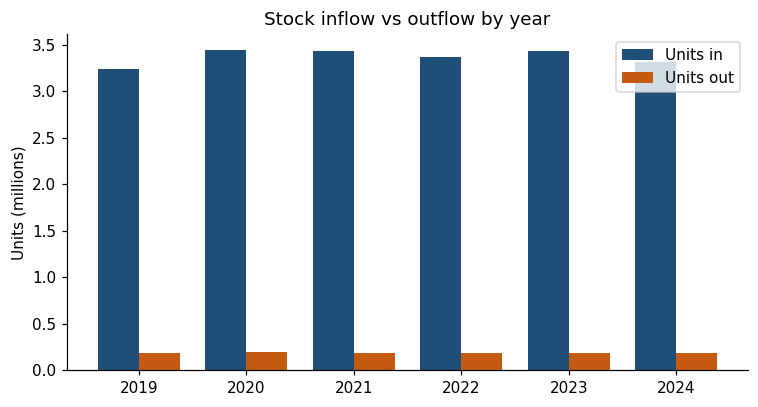

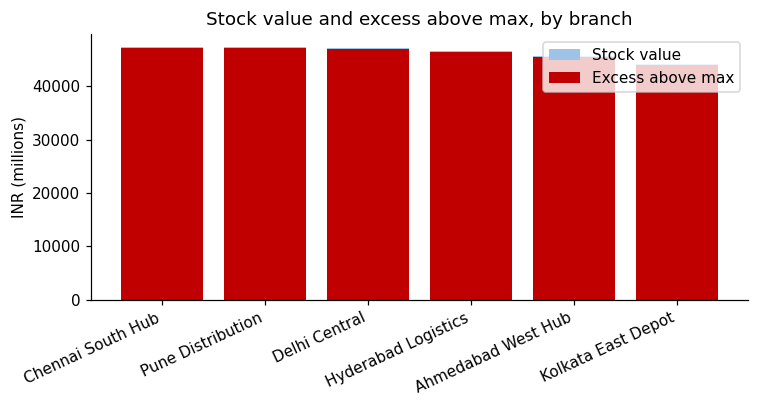

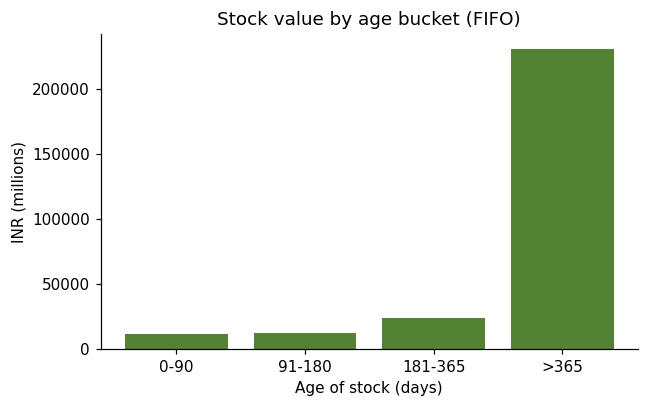

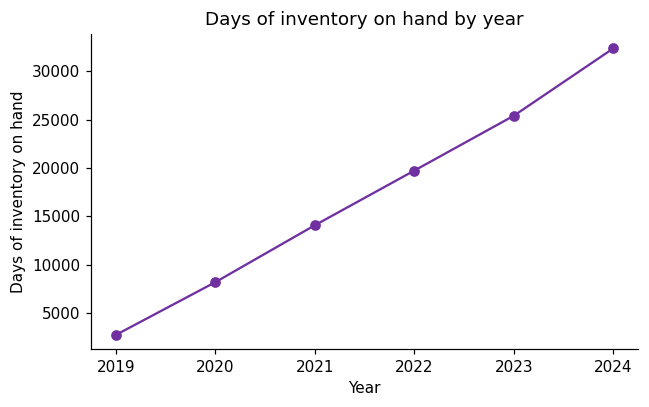

In [24]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# 1. inflow vs outflow by year
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(imb_year)); w = 0.38
ax.bar(x - w/2, imb_year["units_in"] / 1e6, w, label="Units in", color="#1f4e79")
ax.bar(x + w/2, imb_year["units_out"] / 1e6, w, label="Units out", color="#c55a11")
ax.set_xticks(x); ax.set_xticklabels(imb_year["year"])
ax.set_ylabel("Units (millions)"); ax.set_title("Stock inflow vs outflow by year"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "w05_inflow_outflow_by_year.png"); plt.show()

# 2. stock value vs excess value by branch
fig, ax = plt.subplots(figsize=(7, 3.8))
bb = by_branch.sort_values("stock_value", ascending=False)
ax.bar(bb["branch_name"], bb["stock_value"] / 1e6, label="Stock value", color="#9dc3e6")
ax.bar(bb["branch_name"], bb["excess_value"] / 1e6, label="Excess above max", color="#c00000")
ax.set_ylabel("INR (millions)"); ax.set_title("Stock value and excess above max, by branch")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "w05_excess_by_branch.png"); plt.show()

# 3. ageing profile
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(age_tbl.index, age_tbl["value"] / 1e6, color="#548235")
ax.set_xlabel("Age of stock (days)"); ax.set_ylabel("INR (millions)"); ax.set_title("Stock value by age bucket (FIFO)")
fig.tight_layout(); fig.savefig(FIG_DIR / "w05_ageing_profile.png"); plt.show()

# 4. DOH by year
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(t_year["year"], t_year["days_on_hand"], marker="o", color="#7030a0")
ax.set_xlabel("Year"); ax.set_ylabel("Days of inventory on hand"); ax.set_title("Days of inventory on hand by year")
fig.tight_layout(); fig.savefig(FIG_DIR / "w05_doh_by_year.png"); plt.show()

**Reading the output.** Four charts, also saved to `reports/figures/`.
1. **Inflow vs outflow:** the inflow bar towers over the outflow bar in every year. Takeaway: buying, not selling, drives the stock level.
2. **Stock vs excess by branch:** the red part is almost the whole bar. Takeaway: nearly all stock value is above the max level.
3. **Ageing:** the tallest bar is the oldest bucket. Takeaway: most of the capital is more than a year old.
4. **DOH by year:** a line at thousands of days. Takeaway: stock would last many years at current sales.

Check each takeaway against the real chart after running, and edit the sentence if the data says something different.

---
## 10. Output check

In [25]:
expected = ["turnover_doh.csv", "stock_health_status.csv", "inventory_ageing.csv",
            "dead_stock_list.csv", "slow_dead_classification.csv", "week05_headline_metrics.csv"]
pd.DataFrame({"file": [f"week-05/{f}" for f in expected],
              "exists": [(OUT_DIR / f).exists() for f in expected],
              "rows": [len(pd.read_csv(OUT_DIR / f)) if (OUT_DIR / f).exists() else None for f in expected]})

,file,exists,rows
0,week-05/turnover_doh.csv,True,312
1,week-05/stock_health_status.csv,True,180
2,week-05/inventory_ageing.csv,True,180
3,week-05/dead_stock_list.csv,True,0
4,week-05/slow_dead_classification.csv,True,180
5,week-05/week05_headline_metrics.csv,True,14


###### **Reading the output.** A list of every file this notebook should produce, whether it exists and its row count. All rows should show `True`. `dead_stock_list.csv` can legitimately have 0 rows. Rows expected: `stock_health_status.csv` 180, `inventory_ageing.csv` 180, `slow_dead_classification.csv` 180.

---
## 11. Conclusions and next steps

### Task status

| Task | Delivered | Where |
|---|---|---|
| B4 Inventory Turnover | Turnover and DOH by product, category, branch and year | Section 2, `turnover_doh.csv` |
| B5 Stock Health Assessment | Status of all 180 pairs vs branch-level parameters, excess value | Section 3, `stock_health_status.csv` |
| B8 Overstock & Understock | Severity bands, branch and category views, understock test | Section 4 |
| B6 Inventory Aging | FIFO layers, four age buckets, per-pair ageing | Section 5, `inventory_ageing.csv` |
| B3 Slow-Moving & Dead Stock | Recency and cover classification, dead-stock list | Section 6, `dead_stock_list.csv` |
| Root cause (plan, Tuesday) | Inflow vs outflow decomposition, ledger reconciliation | Section 7 |

### Conclusions
Write the final wording after running the notebook, using the numbers in **Section 8**. Four statements are expected to hold, and each should be confirmed against the output before it is written down:

1. **Every pair is overstocked.** All 180 pairs are above their branch maximum. Of the ₹278.77 billion of stock, ₹277.93 billion (99.70%) is above max, and no pair is at or below its reorder point.
2. **Stock almost does not turn.** Turnover in 2024 was 0.01 times a year, which is 32,334 days of inventory on hand. At current sales the excess would take 1,141 months (95 years) to sell.
3. **Most of the capital is old.** 82.72% of stock value is older than 365 days, and only 4.26% arrived in the last 90 days.
4. **The cause is the purchase quantity.** Stock in is 18.03 times stock out. Purchase lines average 159.85 units against 10.50 for sales lines (15.23 times larger), while purchases have only 1.18 times as many lines.
5. **Buying is still going on.** In the last 12 months, ₹50.83 billion of purchase orders (before GST) were placed for pairs already above maximum.

### Limitations
* Opening stock is assumed to be dated 1 Jan 2019, so the age of the oldest layer depends on that assumption.
* ADJUSTMENT movements are excluded because their direction is unknown (issue I08). Their size is shown in Section 1.
* Valuation uses one standard `unit_cost` per product; actual purchase prices are not used.
* A few pairs have a `current_stock` that differs from the ledger (issue I11); the ledger is used throughout.

### Next steps (Week 6 and beyond)
* Hand the excess-value and ageing files to the Week 6 warehouse work (space use by excess stock).
* Use months of cover and the root-cause finding as inputs to the Week 10 safety stock and reorder point work.
* Ask the coordinator about the purchasing rule behind the large purchase lines and the direction of adjustments.

---

**Prepared by:** Keren Oyem · CadetX Virtual Work Experience · Heavy Supplier, Inventory & Warehouse Analytics